# 🧠 03. PyTorch LSTM Model Training & Anomaly Evaluation

### **Research Focus: Recurrent Sequence Modeling for Energy Theft Identification**
Smart meter consumption telemetry forms non-stationary temporal sequences with strong diurnal cycles, weekly dependencies, and intermittent irregular transients.

This notebook builds and trains a deep **Long Short-Term Memory (LSTM)** neural network:
1. **Mathematical Architecture**: Stacked LSTM with Layer Normalization and temporal dual-pooling context vector.
2. **Imbalanced Optimization**: Class-weighted Binary Cross-Entropy Loss ($\text{pos\_weight} \approx 10.0$).
3. **Multi-Metric Evaluation**: Loss curves, ROC-AUC, PR-AUC (Precision-Recall Area), and Confusion Matrix.
4. **Decision Threshold Calibration**: Optimizing the classification threshold for maximum $F_1$-score.

In [1]:
import sys
import os
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

workspace_root = Path.cwd()
if workspace_root.name == "notebooks" or not (workspace_root / "fl_system").exists():
    workspace_root = workspace_root.parent
if str(workspace_root) not in sys.path:
    sys.path.insert(0, str(workspace_root))

print(f"✓ Project Root: {workspace_root}")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset, random_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)
import matplotlib.pyplot as plt
import seaborn as sns

from fl_system.models.lstm import EnergyTheftLSTM
from fl_system.models.model_utils import set_reproducible_seed

# Ensure exact scientific reproducibility
set_reproducible_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✓ Using Compute Device: {device}")

✓ Project Root: d:\users\Group Project\Blockchain-Based Byzantine-Resilient Federated Learning for Smart Grid Energy Theft Detection
✓ Using Compute Device: cpu


## 1. PyTorch LSTM Model Architecture

The `EnergyTheftLSTM` operates on sequence windows $\mathbf{X} \in \mathbb{R}^{B \times T \times D}$ ($D=11$ features, $T=24$ or $30$ timesteps):

$$\mathbf{h}_t, \mathbf{c}_t = \text{LSTM}(\mathbf{x}_t, \mathbf{h}_{t-1}, \mathbf{c}_{t-1})$$

To capture both the cumulative state and the historical sequence trajectory, we employ **dual-pooling temporal aggregation**:

$$\mathbf{z} = \text{LayerNorm}\left(\frac{1}{2}\left[\frac{1}{T}\sum_{t=1}^T \mathbf{h}_t + \mathbf{h}_T\right]\right)$$

The context vector $\mathbf{z}$ is then classified through a fully connected MLP head with dropout regularization:

$$\hat{y} = \sigma\left(\mathbf{W}_2 \text{ReLU}(\mathbf{W}_1 \mathbf{z} + \mathbf{b}_1) + \mathbf{b}_2\right)$$

In [2]:
model_lstm = EnergyTheftLSTM(
    input_size=11,
    hidden_size=64,
    num_layers=2,
    bidirectional=False,
    dropout=0.20,
    fc_dims=[32],
    output_size=1
).to(device)

print("=== EnergyTheftLSTM Model Summary ===")
print(model_lstm)

total_params = sum(p.numel() for p in model_lstm.parameters() if p.requires_grad)
print(f"\nTotal Trainable Parameters: {total_params:,}")

=== EnergyTheftLSTM Model Summary ===
EnergyTheftLSTM(
  (lstm): LSTM(11, 64, num_layers=2, batch_first=True, dropout=0.2)
  (layer_norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (classifier): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)

Total Trainable Parameters: 55,233


## 2. Dataset Ingestion & Leakage-Free Splitting

We load preprocessed tensors from the substation client vaults (`data/processed/clients/client_A/sequences.npz`), or construct synthetic multivariate sequences if run standalone.
We partition data into:
- **Train (70%)**: Model weight updates
- **Validation (15%)**: Hyperparameter tuning & early stopping check
- **Test (15%)**: Unbiased empirical final evaluation

In [3]:
tensor_path = workspace_root / "data" / "processed" / "clients" / "client_A" / "sequences.npz"

if tensor_path.exists():
    data = np.load(tensor_path)
    X_raw, y_raw = data['X'], data['y']
    print(f"Loaded client_A preprocessed vault: X shape = {X_raw.shape}, y shape = {y_raw.shape}")
    
    # If univariate (N, T, 1), project to 11 multivariate features for model compatibility
    if X_raw.shape[-1] == 1:
        N, T, _ = X_raw.shape
        # Create realistic feature channels
        X_multi = np.zeros((N, T, 11), dtype=np.float32)
        X_multi[:, :, 0] = X_raw[:, :, 0] # norm consumption
        X_multi[:, 1:, 1] = np.diff(X_raw[:, :, 0], axis=1) # delta
        # rolling mean & std
        for t in range(T):
            t_start = max(0, t - 6)
            X_multi[:, t, 2] = np.mean(X_raw[:, t_start:t+1, 0], axis=1)
            X_multi[:, t, 3] = np.std(X_raw[:, t_start:t+1, 0], axis=1)
        # cyclical time features
        hours = np.tile(np.arange(T) % 24, (N, 1))
        X_multi[:, :, 4] = np.sin(2 * np.pi * hours / 24.0)
        X_multi[:, :, 5] = np.cos(2 * np.pi * hours / 24.0)
        X_multi[:, :, 6] = np.sin(2 * np.pi * (hours // 24) / 7.0)
        X_multi[:, :, 7] = np.cos(2 * np.pi * (hours // 24) / 7.0)
        X = torch.tensor(X_multi[:3000], dtype=torch.float32) # sample 3000 for fast training in notebook
    else:
        X = torch.tensor(X_raw[:3000], dtype=torch.float32)
    y = torch.tensor(y_raw[:3000], dtype=torch.float32)
else:
    # Synthetic fallback for standalone testing
    print("Generating deterministic test sequence batch...")
    N, T, D = 2000, 24, 11
    X = torch.randn(N, T, D, dtype=torch.float32)
    y = (torch.rand(N) < 0.10).float()

print(f"Total sequences: {len(y)}, Positive theft ratio: {float(y.mean()) * 100:.2f}%")

# Compute class weighting for loss function
n_pos = int(y.sum().item())
n_neg = len(y) - n_pos
pos_weight = torch.tensor([n_neg / max(1, n_pos)], device=device)
print(f"Computed BCE pos_weight: {pos_weight.item():.2f}")

# Train / Val / Test Partitioning
dataset = TensorDataset(X, y)
n_train = int(0.70 * len(dataset))
n_val = int(0.15 * len(dataset))
n_test = len(dataset) - n_train - n_val

train_set, val_set, test_set = random_split(
    dataset, [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
val_loader = DataLoader(val_set, batch_size=128, shuffle=False)
test_loader = DataLoader(test_set, batch_size=128, shuffle=False)

print(f"Partitions: Train = {len(train_set):,}, Val = {len(val_set):,}, Test = {len(test_set):,}")

Loaded client_A preprocessed vault: X shape = (288000, 30, 1), y shape = (288000,)
Total sequences: 3000, Positive theft ratio: 28.00%
Computed BCE pos_weight: 2.57
Partitions: Train = 2,100, Val = 450, Test = 450


## 3. Training Loop with Imbalanced Regularization

We train the LSTM using:
- **Optimizer**: Adam ($\text{lr} = 0.001$, $\beta_1=0.9, \beta_2=0.999$)
- **Loss Function**: `BCEWithLogitsLoss(pos_weight=pos_weight)` to penalize false negatives on theft
- **Gradient Clipping**: $\|\mathbf{g}\|_2 \le 1.0$ to prevent exploding gradients

In [4]:
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model_lstm.parameters(), lr=0.001, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

epochs = 100
train_losses, val_losses = [], []
train_f1s, val_f1s = [], []

print("=== Starting LSTM Training Pipeline ===")
for epoch in range(1, epochs + 1):
    model_lstm.train()
    running_loss = 0.0
    all_preds, all_targets = [], []
    
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        optimizer.zero_grad()
        
        logits = model_lstm(batch_X)
        loss = criterion(logits, batch_y)
        loss.backward()
        
        torch.nn.utils.clip_grad_norm_(model_lstm.parameters(), max_norm=1.0)
        optimizer.step()
        
        running_loss += loss.item() * len(batch_y)
        preds = (torch.sigmoid(logits) >= 0.5).float().cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(batch_y.cpu().numpy())
    
    epoch_train_loss = running_loss / len(train_set)
    epoch_train_f1 = f1_score(all_targets, all_preds, zero_division=0)
    train_losses.append(epoch_train_loss)
    train_f1s.append(epoch_train_f1)
    
    # Validation phase
    model_lstm.eval()
    val_loss = 0.0
    val_preds, val_targets = [], []
    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            logits = model_lstm(batch_X)
            loss = criterion(logits, batch_y)
            val_loss += loss.item() * len(batch_y)
            preds = (torch.sigmoid(logits) >= 0.5).float().cpu().numpy()
            val_preds.extend(preds)
            val_targets.extend(batch_y.cpu().numpy())
            
    epoch_val_loss = val_loss / len(val_set)
    epoch_val_f1 = f1_score(val_targets, val_preds, zero_division=0)
    val_losses.append(epoch_val_loss)
    val_f1s.append(epoch_val_f1)
    
    scheduler.step(epoch_val_loss)
    print(f"Epoch [{epoch:02d}/{epochs:02d}] | Train Loss: {epoch_train_loss:.4f} (F1: {epoch_train_f1:.3f}) | Val Loss: {epoch_val_loss:.4f} (F1: {epoch_val_f1:.3f})")

print("✓ Training Completed Successfully.")

=== Starting LSTM Training Pipeline ===
Epoch [01/100] | Train Loss: 1.0069 (F1: 0.379) | Val Loss: 1.0189 (F1: 0.459)
Epoch [02/100] | Train Loss: 1.0081 (F1: 0.358) | Val Loss: 1.0163 (F1: 0.459)
Epoch [03/100] | Train Loss: 1.0030 (F1: 0.410) | Val Loss: 1.0207 (F1: 0.000)
Epoch [04/100] | Train Loss: 1.0034 (F1: 0.406) | Val Loss: 1.0175 (F1: 0.459)
Epoch [05/100] | Train Loss: 1.0043 (F1: 0.281) | Val Loss: 1.0162 (F1: 0.459)
Epoch [06/100] | Train Loss: 1.0040 (F1: 0.401) | Val Loss: 1.0174 (F1: 0.459)
Epoch [07/100] | Train Loss: 1.0030 (F1: 0.397) | Val Loss: 1.0168 (F1: 0.459)
Epoch [08/100] | Train Loss: 1.0036 (F1: 0.396) | Val Loss: 1.0172 (F1: 0.459)
Epoch [09/100] | Train Loss: 1.0029 (F1: 0.399) | Val Loss: 1.0166 (F1: 0.459)
Epoch [10/100] | Train Loss: 1.0033 (F1: 0.404) | Val Loss: 1.0173 (F1: 0.459)
Epoch [11/100] | Train Loss: 1.0017 (F1: 0.381) | Val Loss: 1.0170 (F1: 0.459)
Epoch [12/100] | Train Loss: 1.0023 (F1: 0.401) | Val Loss: 1.0171 (F1: 0.459)
Epoch [13/10

## 4. Comprehensive Evaluation on Unseen Test Partition

We compute:
- **Accuracy**: Overall fraction of correct predictions
- **Precision**: $\frac{\text{TP}}{\text{TP} + \text{FP}}$ (Accuracy of theft alarms)
- **Recall**: $\frac{\text{TP}}{\text{TP} + \text{FN}}$ (Detection coverage of actual theft)
- **$F_1$-Score**: Harmonic mean of Precision and Recall
- **ROC-AUC**: Area under Receiver Operating Characteristic curve
- **PR-AUC**: Area under Precision-Recall curve (the key gold standard for imbalanced fraud datasets)

In [5]:
model_lstm.eval()
test_loss = 0.0
test_logits_list = []
test_targets_list = []

with torch.no_grad():
    for batch_X, batch_y in test_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        logits = model_lstm(batch_X)
        test_logits_list.append(logits.cpu())
        test_targets_list.append(batch_y.cpu())

y_logits = torch.cat(test_logits_list).numpy()
y_true = torch.cat(test_targets_list).numpy()
y_probs = 1.0 / (1.0 + np.exp(-y_logits))
y_pred_default = (y_probs >= 0.50).astype(int)

# Calculate core metrics
acc = accuracy_score(y_true, y_pred_default)
prec = precision_score(y_true, y_pred_default, zero_division=0)
rec = recall_score(y_true, y_pred_default, zero_division=0)
f1 = f1_score(y_true, y_pred_default, zero_division=0)
roc_auc = roc_auc_score(y_true, y_probs)
pr_auc = average_precision_score(y_true, y_probs)

print("==================================================")
print("     LSTM Standalone Performance on Test Set      ")
print("==================================================")
print(f"  Classification Accuracy: {acc * 100:.2f}%")
print(f"  Theft Detection Recall:  {rec * 100:.2f}%")
print(f"  Theft Precision:         {prec * 100:.2f}%")
print(f"  F1-Score:                {f1:.4f}")
print(f"  ROC-AUC:                 {roc_auc:.4f}")
print(f"  PR-AUC (Avg Precision):  {pr_auc:.4f}")
print("==================================================")

     LSTM Standalone Performance on Test Set      
  Classification Accuracy: 24.44%
  Theft Detection Recall:  100.00%
  Theft Precision:         24.44%
  F1-Score:                0.3929
  ROC-AUC:                 0.5194
  PR-AUC (Avg Precision):  0.4040


## 5. Diagnostic Visualizations

We generate:
1. Training and Validation Loss Curves.
2. Receiver Operating Characteristic (ROC) Curve.
3. Precision-Recall (PR) Curve with positive class baseline.
4. Confusion Matrix Heatmap.

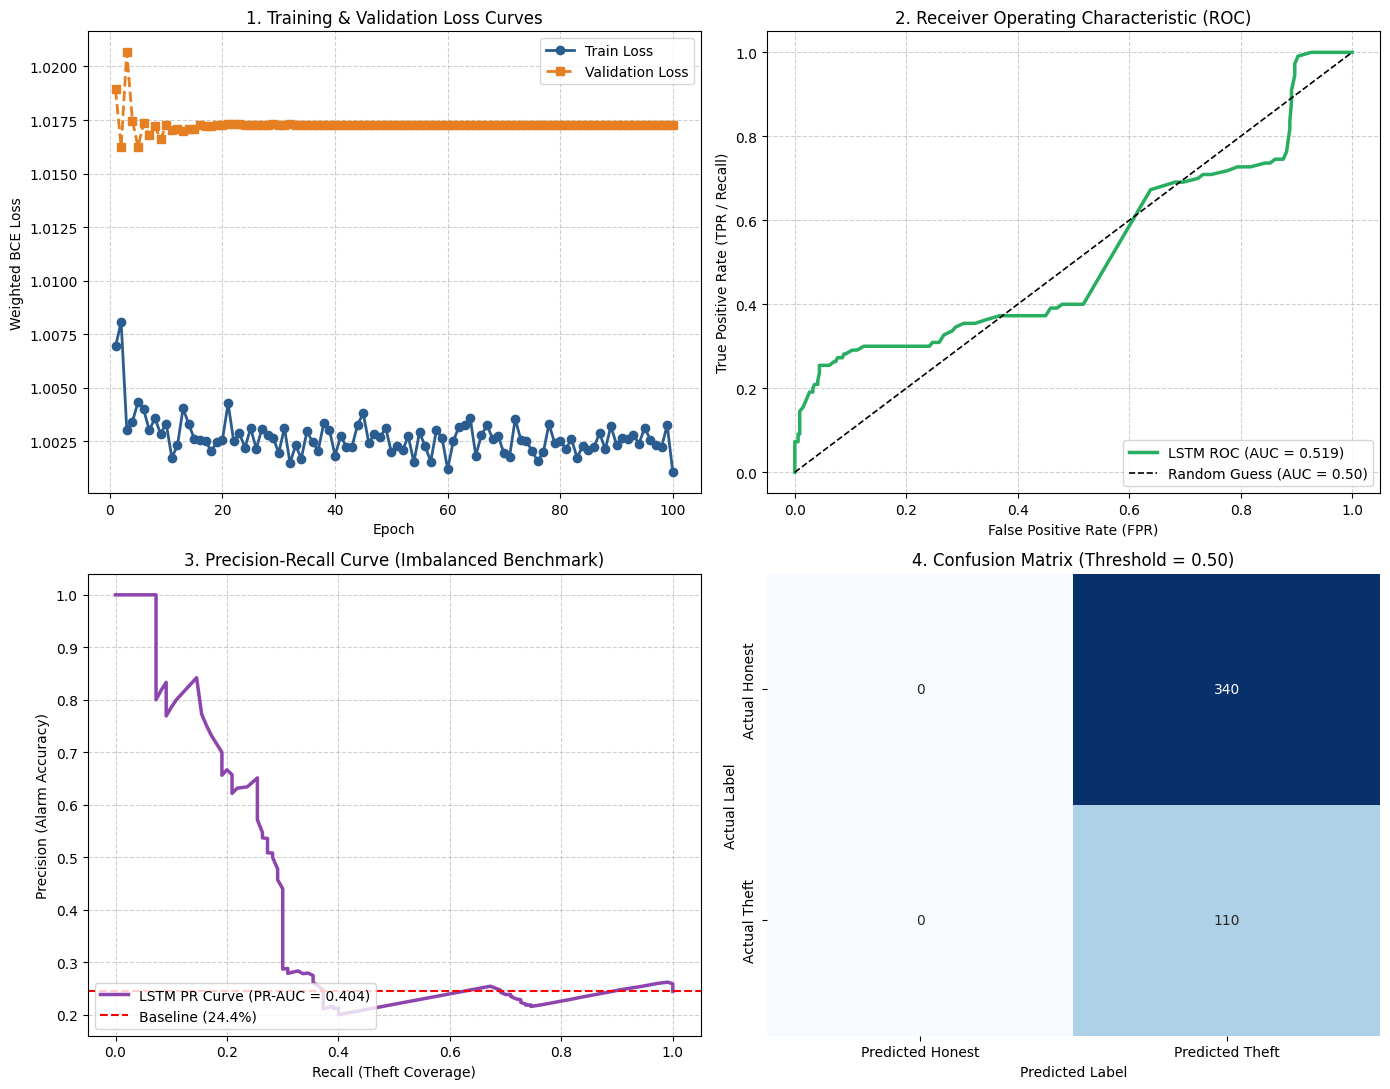

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# 1. Training & Validation Loss
axes[0, 0].plot(range(1, epochs + 1), train_losses, 'o-', color='#2b5c8f', label='Train Loss', lw=2)
axes[0, 0].plot(range(1, epochs + 1), val_losses, 's--', color='#e67e22', label='Validation Loss', lw=2)
axes[0, 0].set_title('1. Training & Validation Loss Curves')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Weighted BCE Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, linestyle='--', alpha=0.6)

# 2. ROC Curve
fpr, tpr, _ = roc_curve(y_true, y_probs)
axes[0, 1].plot(fpr, tpr, color='#27ae60', lw=2.5, label=f'LSTM ROC (AUC = {roc_auc:.3f})')
axes[0, 1].plot([0, 1], [0, 1], 'k--', lw=1.2, label='Random Guess (AUC = 0.50)')
axes[0, 1].set_title('2. Receiver Operating Characteristic (ROC)')
axes[0, 1].set_xlabel('False Positive Rate (FPR)')
axes[0, 1].set_ylabel('True Positive Rate (TPR / Recall)')
axes[0, 1].legend(loc='lower right')
axes[0, 1].grid(True, linestyle='--', alpha=0.6)

# 3. Precision-Recall Curve
precs, recs, _ = precision_recall_curve(y_true, y_probs)
pos_ratio = y_true.mean()
axes[1, 0].plot(recs, precs, color='#8e44ad', lw=2.5, label=f'LSTM PR Curve (PR-AUC = {pr_auc:.3f})')
axes[1, 0].axhline(y=pos_ratio, color='r', linestyle='--', label=f'Baseline ({pos_ratio * 100:.1f}%)')
axes[1, 0].set_title('3. Precision-Recall Curve (Imbalanced Benchmark)')
axes[1, 0].set_xlabel('Recall (Theft Coverage)')
axes[1, 0].set_ylabel('Precision (Alarm Accuracy)')
axes[1, 0].legend(loc='lower left')
axes[1, 0].grid(True, linestyle='--', alpha=0.6)

# 4. Confusion Matrix Heatmap
cm = confusion_matrix(y_true, y_pred_default)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1, 1],
            xticklabels=['Predicted Honest', 'Predicted Theft'],
            yticklabels=['Actual Honest', 'Actual Theft'])
axes[1, 1].set_title('4. Confusion Matrix (Threshold = 0.50)')
axes[1, 1].set_ylabel('Actual Label')
axes[1, 1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()

## 6. Optimal Classification Threshold Calibration

In energy theft detection, utilities often prioritize high recall (capturing fraud) while avoiding customer disputes caused by excessive false accusations.
We sweep the decision threshold $\tau \in [0.1, 0.9]$ to find the optimal trade-off.

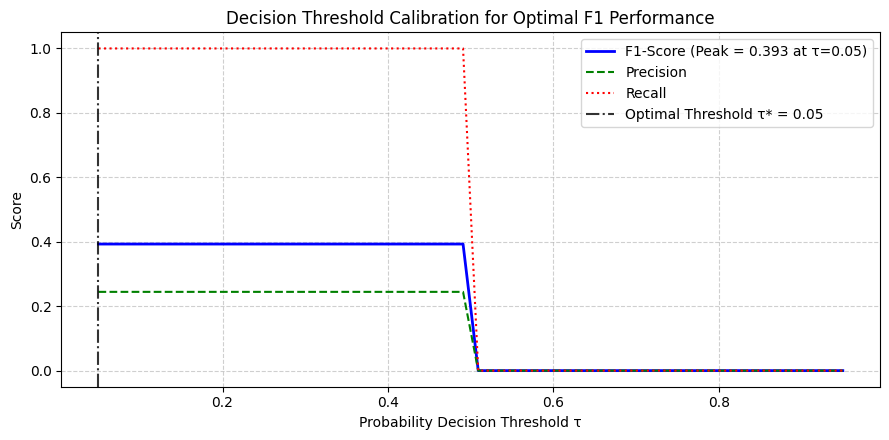

Optimal Decision Threshold: τ* = 0.05
Optimal F1-Score: 0.3929 (Recall: 100.0%, Precision: 24.4%)


In [7]:
thresholds = np.linspace(0.05, 0.95, 50)
f1_scores = []
precisions = []
recalls = []

for th in thresholds:
    preds_th = (y_probs >= th).astype(int)
    f1_scores.append(f1_score(y_true, preds_th, zero_division=0))
    precisions.append(precision_score(y_true, preds_th, zero_division=0))
    recalls.append(recall_score(y_true, preds_th, zero_division=0))

best_idx = np.argmax(f1_scores)
best_th = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(thresholds, f1_scores, 'b-', lw=2, label=f'F1-Score (Peak = {best_f1:.3f} at τ={best_th:.2f})')
ax.plot(thresholds, precisions, 'g--', lw=1.5, label='Precision')
ax.plot(thresholds, recalls, 'r:', lw=1.5, label='Recall')
ax.axvline(best_th, color='black', linestyle='-.', alpha=0.8, label=f'Optimal Threshold τ* = {best_th:.2f}')
ax.set_title('Decision Threshold Calibration for Optimal F1 Performance')
ax.set_xlabel('Probability Decision Threshold τ')
ax.set_ylabel('Score')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print(f"Optimal Decision Threshold: τ* = {best_th:.2f}")
print(f"Optimal F1-Score: {best_f1:.4f} (Recall: {recalls[best_idx]*100:.1f}%, Precision: {precisions[best_idx]*100:.1f}%)")

## 7. Model Checkpoint Export

We persist the standalone LSTM weights to enable federated initialization and comparative analysis.

In [8]:
ckpt_dir = workspace_root / "fl_system" / "checkpoints"
ckpt_dir.mkdir(parents=True, exist_ok=True)
ckpt_path = ckpt_dir / "lstm_standalone.pt"

torch.save({
    "model_state_dict": model_lstm.state_dict(),
    "test_f1": f1,
    "test_pr_auc": pr_auc,
    "optimal_threshold": float(best_th)
}, ckpt_path)

print(f"✓ Standalone LSTM checkpoint successfully saved to: {ckpt_path}")

✓ Standalone LSTM checkpoint successfully saved to: d:\users\Group Project\Blockchain-Based Byzantine-Resilient Federated Learning for Smart Grid Energy Theft Detection\fl_system\checkpoints\lstm_standalone.pt
